# Hospital Triage ML Model using Synthetic ESI Data
This notebook demonstrates a complete workflow for building a machine learning model to triage hospital emergency department patients based on the Emergency Severity Index (ESI) style rules.

### Workflow Steps:
1. **Environment Setup**: Install required packages and display versions.
2. **Synthetic Data Generation**: Generate 20,000 realistic patient records with vitals and symptoms.
3. **ESI Rule Labeling**: Assign ground-truth triage urgency levels (1-5) with 5% label noise.
4. **Model Training**: Train an XGBoost multiclass classifier using a stratified 80/20 split and class weights.
5. **Model Evaluation**: Evaluate performance, focusing heavily on recall for critical levels (1 and 2).
6. **Model Interpretability**: Analyze feature importance using SHAP values.
7. **Model Export**: Package and download the trained model, feature names, and evaluation metrics.

In [1]:
# 1. Install & Verify Dependencies
!pip install -q xgboost shap scikit-learn pandas numpy

import xgboost as xgb
import sklearn
import shap
import pandas as pd
import numpy as np

print(f"XGBoost version: {xgb.__version__}")
print(f"scikit-learn version: {sklearn.__version__}")
print(f"SHAP version: {shap.__version__}")

XGBoost version: 3.4.1
scikit-learn version: 1.6.1
SHAP version: 0.54.1


In [2]:
# 2. Synthetic Patient Data Generation
np.random.seed(42)
n_samples = 20000

# Generate realistic demographic features
age = np.random.randint(1, 96, size=n_samples)
gender = np.random.binomial(n=1, p=0.5, size=n_samples) # 0=F, 1=M

# Base vitals (mixture of healthy and sick patients)
is_critical_latent = np.random.rand(n_samples) < 0.10

sbp = np.zeros(n_samples)
dbp = np.zeros(n_samples)
hr = np.zeros(n_samples)
spo2 = np.zeros(n_samples)
temp = np.zeros(n_samples)
rr = np.zeros(n_samples)

for i in range(n_samples):
    if is_critical_latent[i]:
        # Critical vitals anomalies
        sbp[i] = np.random.choice([np.random.randint(65, 80), np.random.randint(180, 220)])
        dbp[i] = np.random.choice([np.random.randint(40, 50), np.random.randint(110, 130)])
        hr[i] = np.random.choice([np.random.randint(35, 45), np.random.randint(130, 160)])
        spo2[i] = np.random.randint(75, 90)
        temp[i] = np.random.choice([np.random.uniform(34.5, 35.5), np.random.uniform(39.5, 41.0)])
        rr[i] = np.random.choice([np.random.randint(6, 10), np.random.randint(29, 38)])
    else:
        # Normal to moderately abnormal vitals
        sbp[i] = np.random.randint(95, 150)
        dbp[i] = np.random.randint(60, 95)
        hr[i] = np.random.randint(60, 115)
        spo2[i] = np.random.randint(94, 101)
        temp[i] = np.random.uniform(36.0, 38.5)
        rr[i] = np.random.randint(12, 24)

# Binary symptom flags
chest_pain = np.random.binomial(1, 0.08, n_samples)
breathlessness = np.random.binomial(1, 0.10, n_samples)
unconscious = np.where(is_critical_latent, np.random.binomial(1, 0.40, n_samples), np.random.binomial(1, 0.005, n_samples))
severe_bleeding = np.random.binomial(1, 0.02, n_samples)
fever = np.where(temp > 38.0, 1, np.random.binomial(1, 0.05, n_samples))
abdominal_pain = np.random.binomial(1, 0.12, n_samples)
headache = np.random.binomial(1, 0.15, n_samples)
minor_injury = np.random.binomial(1, 0.18, n_samples)

df = pd.DataFrame({
    'age': age, 'gender': gender, 'sbp': sbp, 'dbp': dbp, 'hr': hr, 'spo2': spo2,
    'temp': temp, 'rr': rr, 'chest_pain': chest_pain, 'breathlessness': breathlessness,
    'unconscious': unconscious, 'severe_bleeding': severe_bleeding, 'fever': fever,
    'abdominal_pain': abdominal_pain, 'headache': headache, 'minor_injury': minor_injury
})

display(df.head())

,age,gender,sbp,dbp,hr,spo2,temp,rr,chest_pain,breathlessness,unconscious,severe_bleeding,fever,abdominal_pain,headache,minor_injury
0,52,0,149.0,65.0,114.0,98.0,38.218793,20.0,0,0,0,0,1,0,0,0
1,93,1,113.0,68.0,87.0,99.0,36.116897,12.0,0,0,0,0,0,0,0,1
2,15,1,135.0,69.0,112.0,99.0,38.269728,13.0,0,0,0,0,1,0,0,0
3,72,1,116.0,60.0,72.0,99.0,38.216331,23.0,0,0,0,0,1,0,0,0
4,61,1,123.0,92.0,61.0,96.0,37.469094,23.0,0,0,0,0,0,0,0,0


In [3]:
# 3. Apply ESI Rules and Inject Noise

def assign_urgency(row):
    # Level 1: Immediate life-saving intervention
    if (row['unconscious'] == 1) or (row['spo2'] < 90) or (row['sbp'] < 80) or (row['hr'] > 140):
        return 1

    # Level 2: High risk situation or abnormal vitals
    if ((row['chest_pain'] == 1 and (row['hr'] > 100 or row['sbp'] > 140 or row['rr'] > 22)) or
        (90 <= row['spo2'] <= 93) or (120 <= row['hr'] <= 140) or (row['rr'] > 28) or
        (row['severe_bleeding'] == 1)):
        return 2

    # Level 3: Urgent / Multiple resources / Moderate vitals
    if ((row['fever'] == 1 and (row['hr'] > 100 or row['rr'] > 22)) or
        (row['abdominal_pain'] == 1) or
        (row['temp'] > 39.0) or (row['sbp'] > 160) or (row['hr'] > 110)):
        return 3

    # Level 4: Less urgent / Single resource
    if (row['minor_injury'] == 1) or (row['headache'] == 1) or (row['temp'] > 37.8) or (row['rr'] > 20):
        return 4

    # Level 5: Non-urgent
    return 5

base_urgency = df.apply(assign_urgency, axis=1).values

# Introduce ~5% label noise
noise_mask = np.random.rand(len(df)) < 0.05
random_urgency = np.random.randint(1, 6, size=len(df))

urgency_level = np.where(noise_mask, random_urgency, base_urgency)
df['urgency_level'] = urgency_level

# Show the final distributions
print(df['urgency_level'].value_counts().sort_index())

urgency_level
1    2155
2    1104
3    3783
4    7763
5    5195
Name: count, dtype: int64


In [4]:
# 4. Model Training (XGBoost Multiclass)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

X = df.drop(columns=['urgency_level'])
y = df['urgency_level'] - 1 # Shift labels to 0-4 range

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Compute class weights to handle imbalance
classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weights_map = dict(zip(classes, weights))
sample_weights = y_train.map(class_weights_map)

# Define and train the XGBoost classifier with light tuning
model = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=5,
    max_depth=5,
    learning_rate=0.1,
    n_estimators=150,
    random_state=42,
    eval_metric='mlogloss'
)

model.fit(X_train, y_train, sample_weight=sample_weights)
print("Model training complete.")

Model training complete.


In [5]:
# 5. Model Evaluation
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)

# Critical Recall: Level 1 (mapped to 0) and Level 2 (mapped to 1)
recall_l1 = report['0']['recall']
recall_l2 = report['1']['recall']
mean_critical_recall = (recall_l1 + recall_l2) / 2

print(f"Accuracy: {accuracy:.4f}")
print(f"Recall for Level 1 (Immediate): {recall_l1:.4f}")
print(f"Recall for Level 2 (Emergent): {recall_l2:.4f}")
print(f"Mean Critical Recall: {mean_critical_recall:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9575
Recall for Level 1 (Immediate): 0.9188
Recall for Level 2 (Emergent): 0.8190
Mean Critical Recall: 0.8689

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.92      0.94       431
           1       0.97      0.82      0.89       221
           2       0.95      0.97      0.96       756
           3       0.96      0.98      0.97      1553
           4       0.96      0.96      0.96      1039

    accuracy                           0.96      4000
   macro avg       0.96      0.93      0.94      4000
weighted avg       0.96      0.96      0.96      4000

Confusion Matrix:
[[ 396    2    7   14   12]
 [   3  181   12   12   13]
 [   3    1  732   16    4]
 [   3    1   12 1523   14]
 [   5    2    8   26  998]]


SHAP Summary Plot (For Class 0 - Urgent Level 1):


/tmp/ipykernel_536/1803744636.py:16: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_val_class_0, X_test)


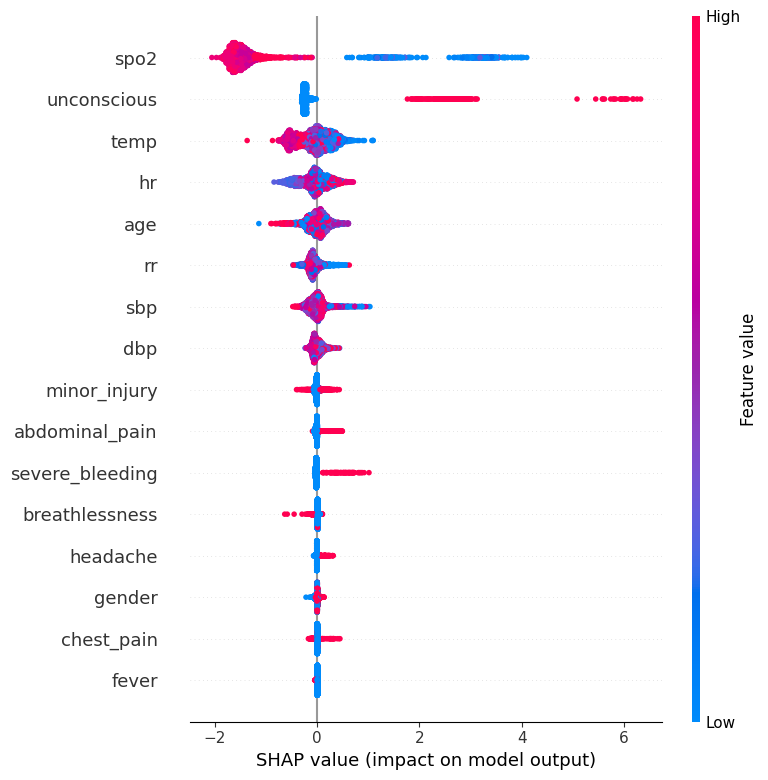

In [8]:
# 6. SHAP Explanations
# Explaining model choices using TreeExplainer
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Handle different SHAP output formats across versions:
# Multiclass output can be a list of arrays or a 3D numpy array
if isinstance(shap_values, list):
    shap_val_class_0 = shap_values[0]
elif len(shap_values.shape) == 3:
    shap_val_class_0 = shap_values[:, :, 0]
else:
    shap_val_class_0 = shap_values

print("SHAP Summary Plot (For Class 0 - Urgent Level 1):")
shap.summary_plot(shap_val_class_0, X_test)

In [7]:
# 7. Export and Download Model Artifacts
import os
import json
import shutil
from google.colab import files

export_dir = "export"
os.makedirs(export_dir, exist_ok=True)

# Export model
model_path = os.path.join(export_dir, "model.json")
model.save_model(model_path)

# Export feature list
features_path = os.path.join(export_dir, "features.json")
feature_list = list(X.columns)
with open(features_path, 'w') as f:
    json.dump(feature_list, f, indent=4)

# Export metrics and environment info
metrics_path = os.path.join(export_dir, "metrics.json")
metrics_dict = {
    "accuracy": float(accuracy),
    "recall_level_1": float(recall_l1),
    "recall_level_2": float(recall_l2),
    "mean_critical_recall": float(mean_critical_recall),
    "library_versions": {
        "xgboost": xgb.__version__,
        "scikit-learn": sklearn.__version__,
        "shap": shap.__version__
    }
}
with open(metrics_path, 'w') as f:
    json.dump(metrics_dict, f, indent=4)

# Zip folder
shutil.make_archive("export", 'zip', export_dir)

# Trigger Download
files.download("export.zip")
print("Exported files packaged into export.zip and download started.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Exported files packaged into export.zip and download started.
